# Simple Image Viewer

Scorer なし。データセット画像（real / generated）の閲覧とピクセルレベルの統計可視化。

| セクション | 内容 |
|---|---|
| **Sec 0** | インポート＋設定（ここだけ書き換えて使う） |
| **Sec 1** | データセット概要 |
| **Sec 2** | 文字別 Image Grid |
| **Sec 3** | フォント別 Image Grid |
| **Sec 4** | ピクセル統計（輝度・ストローク密度） |
| **Sec 5** | 文字カバレッジ ヒートマップ |
| **Sec 6** | フォント間ばらつき（文字ごとのピクセル分散） |
| **Sec 7** | 論文用グリッド（文字×フォントの均等サンプリング） |

## Sec 0: インポート & 設定

In [32]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 8

In [33]:
# ── 設定（このセルだけ書き換えて使う） ─────────────────────────────────
# DATA_DIR = Path("data/datasets/font2dataset_google_uppercase_96_sdf")  # images/ + metadata.parquet の親ディレクトリ
DATA_DIR = Path("results/2026-06-17-16-48_diffusion_uppercase_sdf/checkpoints/last-ema")  # images/ + metadata.parquet の親ディレクトリ
CHARSET  = None    # None=全文字。"ABCDE" など指定すると絞り込む

# Sec 2: 文字別グリッド
VIEW_CHARS  = "H"  # 表示したい文字（文字列でも list でも可）
N_PER_CHAR  = 64       # 1 文字あたりの表示枚数

# Sec 3: フォント別グリッド
VIEW_FAMILY = "generated"  # real フォントなら "ABeeZee" 等。generated なら "generated"
VIEW_STYLE  = None         # None=全スタイル。"Regular" や "st100_cs1.0" など指定も可

# Sec 4: ピクセル統計
N_STAT_SAMPLES = 2000   # 統計計算に使う画像数（全体からランダムサンプリング）

# Sec 5: カバレッジヒートマップ
MAX_FAMILY = 60   # 最大行数（これを超える場合はランダムサンプリング）

# Sec 6: フォント間ばらつき
N_VAR_SAMPLES = 30   # 1 文字あたりのサンプル数

RANDOM_SEED = 42

# 後処理（２値化）— None で無効
BINARIZE_THRESHOLD = None   # 例: 0.5。これ以上の輝度を白(1)、未満を黒(0)に変換
                            # "otsu" で大津の二値化（画像ごとに最適閾値を自動決定）
BINARIZE_SHARPNESS = None   # None でハード閾値。20〜50 でソフト sigmoid（グレー画像のエッジ改善）
                            # BINARIZE_THRESHOLD="otsu" のときは無視される
# ────────────────────────────────────────────────────────────────────────

In [34]:
import math
from skimage.filters import threshold_otsu

def load_image(file: str) -> np.ndarray:
    """PNG を 2D float32 配列 [0, 1] として読み込む。"""
    img = mpimg.imread(str(DATA_DIR / "images" / file))
    img = np.squeeze(img)       # (H, W, 1) → (H, W)
    if img.ndim == 3:           # RGB/RGBA → grayscale
        img = img[..., :3].mean(axis=2)
    if img.dtype == np.uint8:   # PNG は通常 float32 だが念のため正規化
        img = img.astype(np.float32) / 255.0
    img = img.astype(np.float32)
    if BINARIZE_THRESHOLD is not None:
        if BINARIZE_THRESHOLD == "otsu":
            thresh = threshold_otsu(img)
            img = (img >= thresh).astype(np.float32)
        elif BINARIZE_SHARPNESS is not None:
            img = (1.0 / (1.0 + np.exp(-(img - BINARIZE_THRESHOLD) * BINARIZE_SHARPNESS))).astype(np.float32)
        else:
            img = (img >= BINARIZE_THRESHOLD).astype(np.float32)
    return img


def show_image_grid(
    df: pd.DataFrame,
    title: str,
    label_col: str = "font_family",
    n_cols: int | None = None,
    img_size: float = 1.2,
) -> None:
    """DataFrame の画像を N×M グリッドで表示する。n_cols=None で正方形に近いグリッドを自動計算。"""
    n = len(df)
    if n == 0:
        print(f"[SKIP] No images to show for '{title}'")
        return
    if n_cols is None:
        n_cols = math.ceil(math.sqrt(n))
    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(n_cols * img_size, n_rows * (img_size + 0.4)),
        squeeze=False,
    )
    for idx in range(n_rows * n_cols):
        r, c = divmod(idx, n_cols)
        ax = axes[r, c]
        ax.axis("off")
        if idx < n:
            row = df.iloc[idx]
            try:
                img = load_image(row["file"])
                ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            except Exception:
                pass
            sub = str(row.get(label_col, ""))[:22]
            ax.set_title(sub, fontsize=6, pad=2)

    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()


def show_image_rows(
    row_data: list,
    n_per_row: int,
    title: str,
    label_col: str = "font_family",
    img_size: float = 1.2,
) -> None:
    """
    row_data : list of (row_label, DataFrame)
    n_per_row: 1 行あたりの最大枚数
    label_col: サブタイトルに使うメタデータ列
    """
    n_rows = len(row_data)
    n_cols = n_per_row
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(n_cols * img_size, n_rows * (img_size + 0.5)),
        squeeze=False,
    )
    for r, (row_label, df) in enumerate(row_data):
        axes[r, 0].set_ylabel(str(row_label), rotation=0, labelpad=55, va="center", fontsize=9)
        for c in range(n_cols):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(df):
                row = df.iloc[c]
                try:
                    img = load_image(row["file"])
                    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
                except Exception:
                    pass
                sub = str(row.get(label_col, ""))[:22]
                ax.set_title(sub, fontsize=6, pad=2)
    fig.suptitle(title, fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()

---
## Sec 1: Dataset Overview

Generated font dataset
  Images     : 98,800
  Characters : 26  ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
  Styles     : 1  ['st100_cs1.0']
  cond_scale            : [np.float64(1.0)]
  sampling_timesteps    : [np.int64(100)]
  use_ema               : [np.True_]


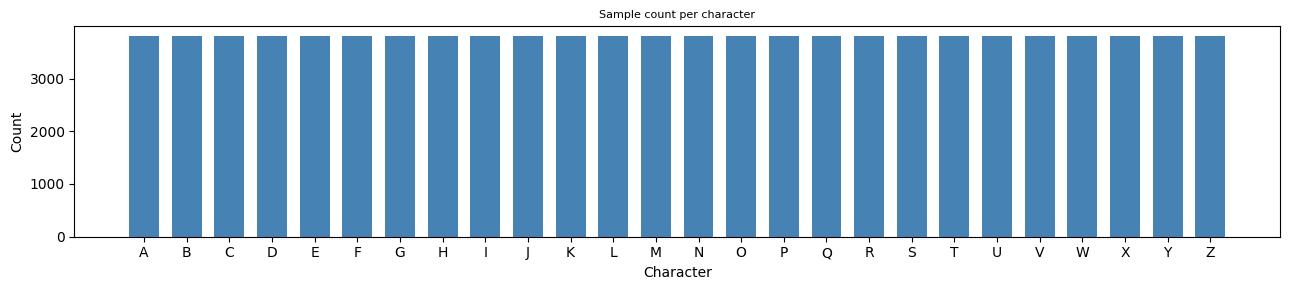

In [35]:
meta = pd.read_parquet(DATA_DIR / "metadata.parquet")
is_generated = (meta["font_family"] == "generated").all()

if CHARSET is not None:
    meta = meta[meta["char"].isin(list(CHARSET))].reset_index(drop=True)

print(f"{'Generated' if is_generated else 'Real'} font dataset")
print(f"  Images     : {len(meta):,}")
print(f"  Characters : {meta['char'].nunique()}  {sorted(meta['char'].unique())}")

if is_generated:
    if "font_style" in meta.columns:
        print(f"  Styles     : {meta['font_style'].nunique()}  {sorted(meta['font_style'].unique())}")
    for col in ["cond_scale", "sampling_timesteps", "use_ema"]:
        if col in meta.columns:
            print(f"  {col:<22s}: {sorted(meta[col].unique())}")
else:
    print(f"  Font families: {meta['font_family'].nunique():,}")
    print(f"  Font styles  : {meta['font_style'].nunique():,}")

# サンプル数の棒グラフ
char_counts = meta.groupby("char").size().sort_index()
fig, ax = plt.subplots(figsize=(max(6, len(char_counts) * 0.5), 3))
ax.bar(char_counts.index, char_counts.values, color="steelblue", width=0.7)
ax.set_xlabel("Character")
ax.set_ylabel("Count")
ax.set_title("Sample count per character")
plt.tight_layout()
plt.show()

---
## Sec 2: Image Grid by Character

`VIEW_CHARS` で指定した文字ごとに `N_PER_CHAR` 枚をランダムサンプリングして表示する。

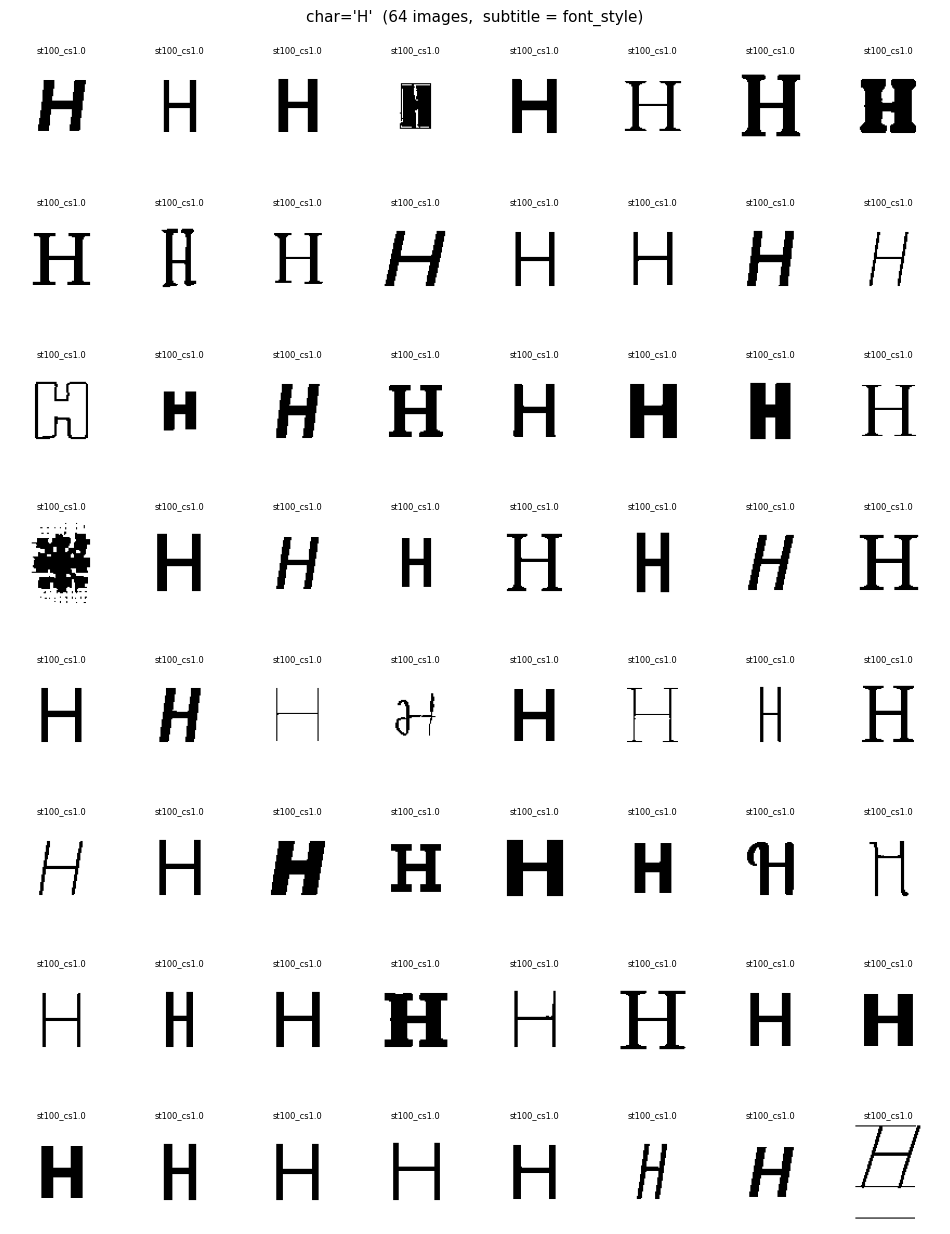

In [36]:
label_col = "font_style" if is_generated else "font_family"
chars = list(VIEW_CHARS)

for ch in chars:
    char_meta = meta[meta["char"] == ch]
    n = min(N_PER_CHAR, len(char_meta))
    if n == 0:
        print(f"[SKIP] char '{ch}' not found in dataset")
        continue
    sample = char_meta.sample(n, random_state=RANDOM_SEED).reset_index(drop=True)
    show_image_grid(
        sample,
        title=f"char='{ch}'  ({n} images,  subtitle = {label_col})",
        label_col=label_col,
    )

---
## Sec 3: Image Grid by Font Family / Style

- **real フォント**: `VIEW_FAMILY` で指定したフォントファミリの全文字を 1 枚ずつ表示。
- **generated**: `VIEW_FAMILY="generated"` で全スタイルを行ごとに表示。`VIEW_STYLE` で絞り込み可能。

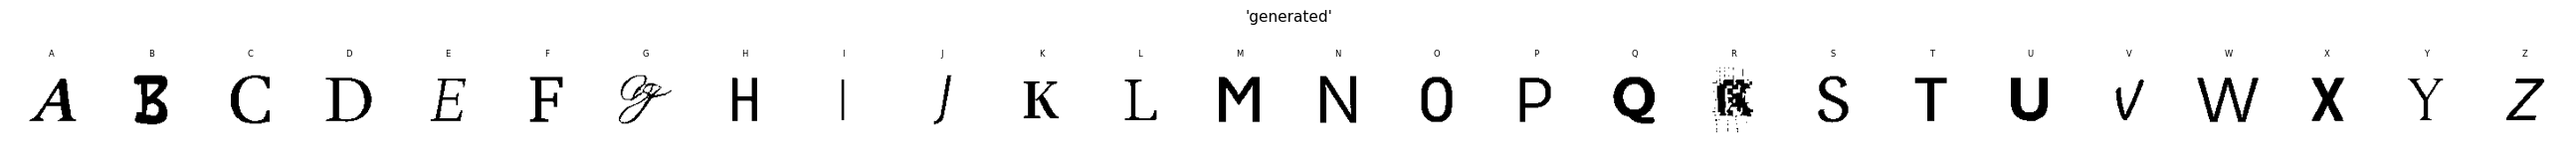

In [37]:
family_meta = meta[meta["font_family"] == VIEW_FAMILY].copy()
if VIEW_STYLE is not None:
    family_meta = family_meta[family_meta["font_style"] == VIEW_STYLE]

if len(family_meta) == 0:
    msg = f"No data found for font_family='{VIEW_FAMILY}'"
    if VIEW_STYLE:
        msg += f", font_style='{VIEW_STYLE}'"
    print(msg)
else:
    chars_sorted = sorted(family_meta["char"].unique())

    if is_generated and VIEW_STYLE is None and "font_style" in family_meta.columns:
        # generated: 1 行 = 1 スタイル, 列 = 文字
        styles = sorted(family_meta["font_style"].unique())
        row_data = []
        for style in styles:
            style_meta = family_meta[family_meta["font_style"] == style]
            one_per_char = (
                style_meta.groupby("char", as_index=False)
                .first()
                .sort_values("char")
                .reset_index(drop=True)
            )
            row_data.append((style, one_per_char))
        label_c = "char"
    else:
        # real: 1 行 = フォントファミリ, 列 = 文字
        one_per_char = (
            family_meta.groupby("char", as_index=False)
            .first()
            .sort_values("char")
            .reset_index(drop=True)
        )
        row_data = [(VIEW_FAMILY, one_per_char)]
        label_c = "char"

    n_cols = max(len(df) for _, df in row_data)
    title = f"'{VIEW_FAMILY}'"
    if VIEW_STYLE:
        title += f" / '{VIEW_STYLE}'"

    show_image_rows(
        row_data,
        n_per_row=n_cols,
        title=title,
        label_col=label_c,
        img_size=1.0,
    )

---
## Sec 4: Pixel Statistics — Brightness & Stroke Density

- **brightness**: 画像全体の平均輝度（白=1, 黒=0）。
- **stroke density**: 暗ピクセル（< 0.5）の割合。フォントのストローク太さの代理指標。

`N_STAT_SAMPLES` 枚をランダムサンプリングして計算する。

Loading 2000 images for pixel statistics …


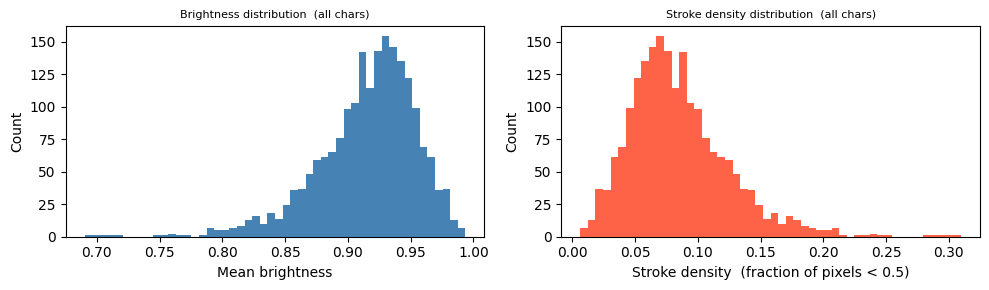

/tmp/ipykernel_536554/1493787400.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(
/tmp/ipykernel_536554/1493787400.py:45: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


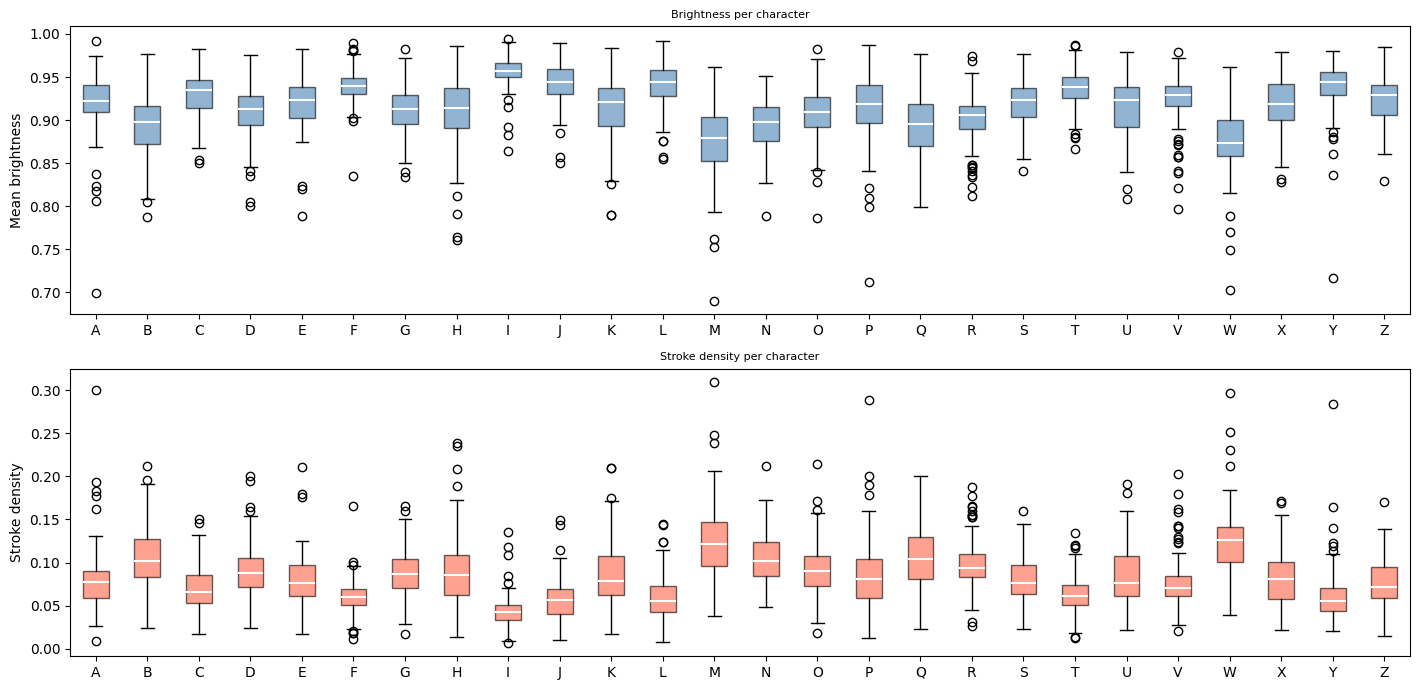

In [38]:
n_stat = min(N_STAT_SAMPLES, len(meta))
print(f"Loading {n_stat} images for pixel statistics …")

stat_meta = meta.sample(n_stat, random_state=RANDOM_SEED).reset_index(drop=True)
brightnesses   = np.empty(n_stat, dtype=np.float32)
stroke_density = np.empty(n_stat, dtype=np.float32)

for i, row in stat_meta.iterrows():
    img = load_image(row["file"])
    brightnesses[i]   = img.mean()
    stroke_density[i] = (img < 0.5).mean()

stat_meta = stat_meta.copy()
stat_meta["brightness"]     = brightnesses
stat_meta["stroke_density"] = stroke_density

# 全体分布
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(brightnesses, bins=50, color="steelblue", edgecolor="none")
axes[0].set_xlabel("Mean brightness")
axes[0].set_ylabel("Count")
axes[0].set_title("Brightness distribution  (all chars)")

axes[1].hist(stroke_density, bins=50, color="tomato", edgecolor="none")
axes[1].set_xlabel("Stroke density  (fraction of pixels < 0.5)")
axes[1].set_ylabel("Count")
axes[1].set_title("Stroke density distribution  (all chars)")
plt.tight_layout()
plt.show()

# 文字ごとのボックスプロット
chars_uniq = sorted(stat_meta["char"].unique())
fig, axes = plt.subplots(2, 1, figsize=(max(8, len(chars_uniq) * 0.55), 7))

data_bright = [stat_meta.loc[stat_meta["char"] == c, "brightness"].values for c in chars_uniq]
axes[0].boxplot(
    data_bright, labels=chars_uniq, patch_artist=True,
    boxprops=dict(facecolor="steelblue", alpha=0.6),
    medianprops=dict(color="white", linewidth=1.5),
)
axes[0].set_ylabel("Mean brightness")
axes[0].set_title("Brightness per character")

data_stroke = [stat_meta.loc[stat_meta["char"] == c, "stroke_density"].values for c in chars_uniq]
axes[1].boxplot(
    data_stroke, labels=chars_uniq, patch_artist=True,
    boxprops=dict(facecolor="tomato", alpha=0.6),
    medianprops=dict(color="white", linewidth=1.5),
)
axes[1].set_ylabel("Stroke density")
axes[1].set_title("Stroke density per character")

plt.tight_layout()
plt.show()

---
## Sec 5: Character Coverage Heatmap

- **real**: 行 = `font_family`、列 = 文字。どのフォントがどの文字を持つかを示す。
- **generated**: 行 = `font_style`（例: `st100_cs1.0`）、列 = 文字。

`font_family` が `MAX_FAMILY` を超える場合はランダムサンプリング。

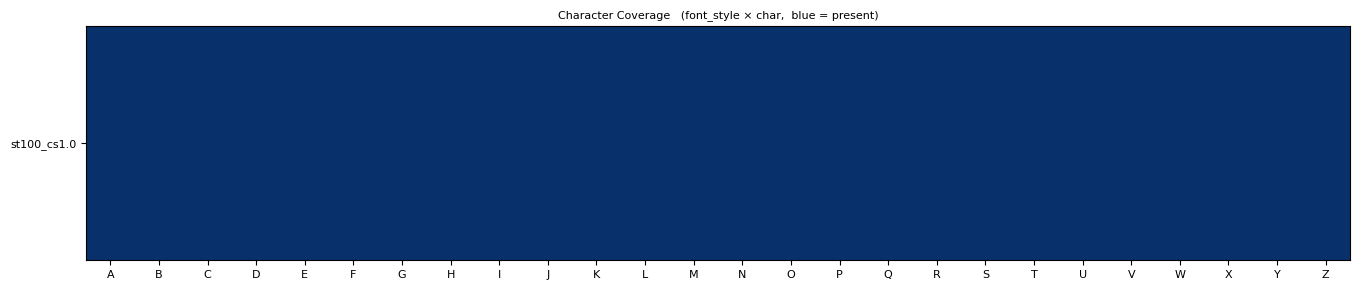

Coverage   : 26 / 26  (100.0%)
Chars with full coverage : 26 / 26


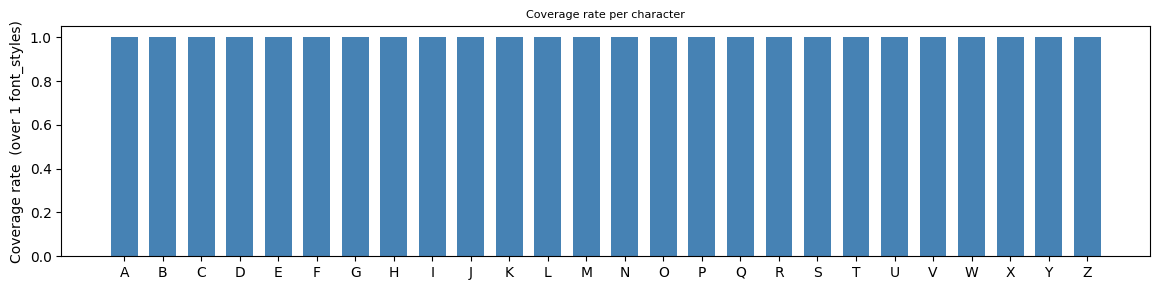

In [39]:
index_col = "font_style" if is_generated else "font_family"

pivot = (
    meta.pivot_table(index=index_col, columns="char", aggfunc="size", fill_value=0) > 0
).astype(int)

if len(pivot) > MAX_FAMILY:
    rng = np.random.default_rng(RANDOM_SEED)
    idx = rng.choice(len(pivot), MAX_FAMILY, replace=False)
    pivot = pivot.iloc[sorted(idx)]
    print(f"[NOTE] {MAX_FAMILY} / {len(meta[index_col].unique())} {index_col}s shown (random sample)")

n_rows, n_cols = pivot.shape
fig_h = max(3, n_rows * 0.20 + 1.5)
fig_w = max(5, n_cols * 0.45 + 2.0)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.imshow(pivot.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)

ax.set_xticks(range(n_cols))
ax.set_xticklabels(pivot.columns, fontsize=8)

if n_rows <= 100:
    tick_fs = max(4, min(8, 180 // n_rows))
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(pivot.index, fontsize=tick_fs)
else:
    ax.set_yticks([])
    ax.set_ylabel(f"{n_rows} {index_col}s  (tick labels hidden — too many)")

ax.set_title(f"Character Coverage   ({index_col} × char,  blue = present)")
plt.tight_layout()
plt.show()

# サマリ統計
total   = n_rows * n_cols
present = int(pivot.values.sum())
print(f"Coverage   : {present} / {total}  ({100 * present / total:.1f}%)")
print(f"Chars with full coverage : {int((pivot.values.sum(axis=0) == n_rows).sum())} / {n_cols}")
if not is_generated:
    print(f"Fonts with full coverage : {int((pivot.values.sum(axis=1) == n_cols).sum())} / {n_rows}")

# 文字ごとのカバレッジ率（棒グラフ）
char_coverage = pivot.values.sum(axis=0) / n_rows
fig, ax = plt.subplots(figsize=(max(5, n_cols * 0.45), 3))
ax.bar(pivot.columns, char_coverage, color="steelblue", width=0.7)
ax.set_ylim(0, 1.05)
ax.set_ylabel(f"Coverage rate  (over {n_rows} {index_col}s)")
ax.set_title("Coverage rate per character")
plt.tight_layout()
plt.show()

---
## Sec 6: Inter-Font Variation

文字ごとに `N_VAR_SAMPLES` 枚をサンプリングし、ピクセルごとの標準偏差を計算する。
平均 std が大きい文字ほどフォント間で見た目の差が大きい（多様）。

> 文字数が多い場合は少し時間がかかる。

Computing pixel-wise std for 26 chars × 30 samples …
Done.


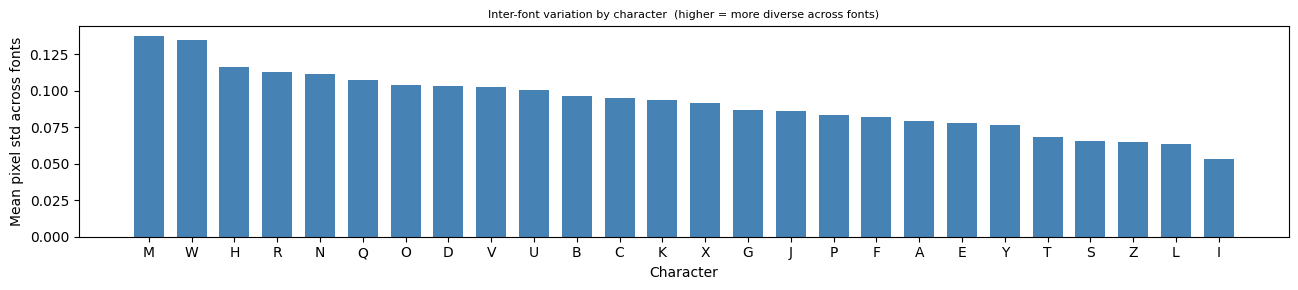

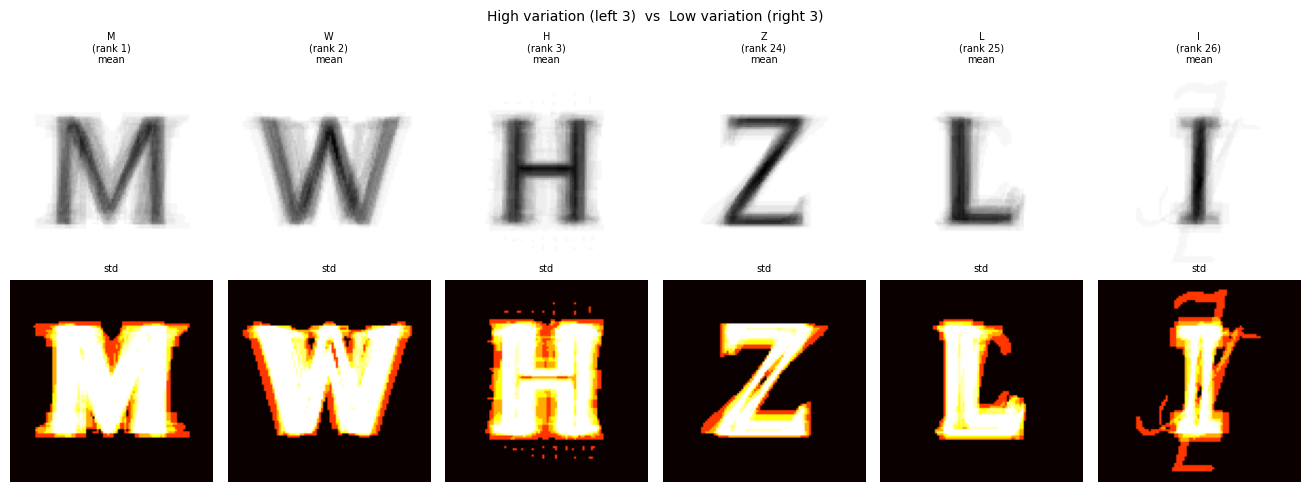

In [40]:
chars_all = sorted(meta["char"].unique())
print(f"Computing pixel-wise std for {len(chars_all)} chars × {N_VAR_SAMPLES} samples …")

var_scores: dict = {}
mean_imgs:  dict = {}
std_imgs:   dict = {}

for ch in chars_all:
    char_meta = meta[meta["char"] == ch]
    n = min(N_VAR_SAMPLES, len(char_meta))
    sample = char_meta.sample(n, random_state=RANDOM_SEED)
    imgs = np.stack([load_image(r["file"]) for _, r in sample.iterrows()])
    mean_imgs[ch]  = imgs.mean(axis=0)
    std_imgs[ch]   = imgs.std(axis=0)
    var_scores[ch] = float(std_imgs[ch].mean())

print("Done.")

# 棒グラフ（分散の大きい順）
sorted_chars = sorted(chars_all, key=lambda c: var_scores[c], reverse=True)
scores = [var_scores[c] for c in sorted_chars]

fig, ax = plt.subplots(figsize=(max(6, len(sorted_chars) * 0.5), 3))
ax.bar(sorted_chars, scores, color="steelblue", width=0.7)
ax.set_xlabel("Character")
ax.set_ylabel("Mean pixel std across fonts")
ax.set_title("Inter-font variation by character  (higher = more diverse across fonts)")
plt.tight_layout()
plt.show()

# 上位・下位 3 文字の平均画像と std マップを表示
n_show = min(3, len(sorted_chars) // 2)
top_chars = sorted_chars[:n_show]
bot_chars  = sorted_chars[-n_show:]
show_chars = top_chars + bot_chars
labels = (
    [f"{c}\n(rank {i+1})" for i, c in enumerate(top_chars)] +
    [f"{c}\n(rank {len(sorted_chars)-n_show+i+1})" for i, c in enumerate(bot_chars)]
)

fig, axes = plt.subplots(2, len(show_chars), figsize=(len(show_chars) * 2.2, 5), squeeze=False)
for col, (ch, lbl) in enumerate(zip(show_chars, labels)):
    axes[0, col].imshow(mean_imgs[ch], cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(f"{lbl}\nmean", fontsize=7)
    axes[0, col].axis("off")
    axes[1, col].imshow(std_imgs[ch],  cmap="hot",  vmin=0, vmax=0.4)
    axes[1, col].set_title("std", fontsize=7)
    axes[1, col].axis("off")

fig.suptitle(
    f"High variation (left {n_show})  vs  Low variation (right {n_show})",
    fontsize=10,
)
plt.tight_layout()
plt.show()

---
## Sec 7: Publication Grid — Balanced Character Sampling

指定した `GRID_CHARSET` から均等にサンプリングし、論文用のグリッド図を生成する。

- 行 = 文字、列 = フォントサンプル（異なるフォントファミリから選出）
- `GRID_SHUFFLE_CHARS=False`（既定）でアルファベット順、`True` でランダム順
- `GRID_SAVE_PATH` を指定すると PDF/PNG で保存

Selected 7 chars: ['A', 'B', 'C', 'D', 'E', 'F', 'G']


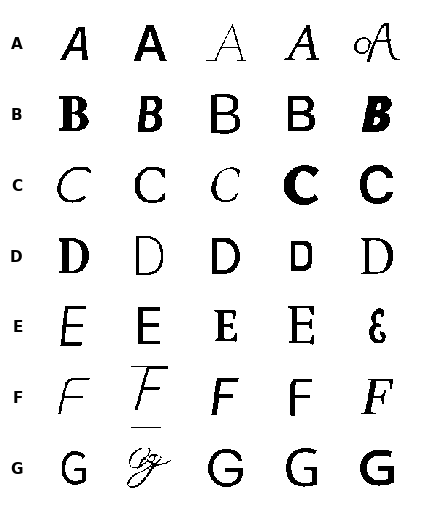

Grid: 7 chars × 5 samples


In [41]:
# ── 設定 ────────────────────────────────────────────────────────────────
GRID_CHARSET = "ABCDEFG"  # 表示する文字集合
GRID_N_CHARS = 26           # 表示する文字数（GRID_CHARSET からサンプリング）
GRID_N_COLS  = 5          # 1 文字あたりの表示枚数（= グリッドの列数）
GRID_SHUFFLE_CHARS = False # True でランダム順 / False でアルファベット順
GRID_IMG_SIZE = 0.7        # 1 画像あたりの表示サイズ (inch)
GRID_PAD = 0.02            # 画像間のパディング (inch)
GRID_SAVE_PATH = None      # 保存先 (例: "fig_font_grid.pdf")。None で保存しない
GRID_SEED = 43
# ────────────────────────────────────────────────────────────────────────

rng = np.random.default_rng(GRID_SEED)

# 文字の選択
available_chars = sorted(set(GRID_CHARSET) & set(meta["char"].unique()))
if len(available_chars) == 0:
    raise ValueError(f"No characters from GRID_CHARSET found in dataset")

n_chars = min(GRID_N_CHARS, len(available_chars))
if GRID_SHUFFLE_CHARS:
    selected_chars = list(rng.choice(available_chars, n_chars, replace=False))
else:
    selected_chars = available_chars[:n_chars]

print(f"Selected {len(selected_chars)} chars: {selected_chars}")

# 各文字から異なるフォントファミリを優先してサンプリング
rows_imgs = []
for ch in selected_chars:
    ch_meta = meta[meta["char"] == ch]
    if not is_generated and "font_family" in ch_meta.columns:
        # 異なるフォントファミリから 1 枚ずつ選ぶ
        families = ch_meta["font_family"].unique()
        chosen_families = rng.choice(
            families, min(GRID_N_COLS, len(families)), replace=False
        )
        samples = []
        for fam in chosen_families:
            fam_rows = ch_meta[ch_meta["font_family"] == fam]
            samples.append(fam_rows.sample(1, random_state=int(rng.integers(1e9))).iloc[0])
        sample_df = pd.DataFrame(samples)
    else:
        n = min(GRID_N_COLS, len(ch_meta))
        sample_df = ch_meta.sample(n, random_state=int(rng.integers(1e9)))

    imgs = []
    for _, row in sample_df.iterrows():
        try:
            imgs.append(load_image(row["file"]))
        except Exception:
            pass
    rows_imgs.append((ch, imgs))

# グリッド描画
n_rows = len(rows_imgs)
n_cols = max(len(imgs) for _, imgs in rows_imgs)
fig_w = n_cols * GRID_IMG_SIZE + 0.6
fig_h = n_rows * GRID_IMG_SIZE + 0.3

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(fig_w, fig_h),
    gridspec_kw={"wspace": GRID_PAD, "hspace": GRID_PAD},
    squeeze=False,
)

for r, (ch, imgs) in enumerate(rows_imgs):
    for c in range(n_cols):
        ax = axes[r, c]
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if c < len(imgs):
            ax.imshow(imgs[c], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        else:
            ax.set_visible(False)
    # 行ラベル（文字）
    axes[r, 0].set_ylabel(
        ch, rotation=0, fontsize=11, fontweight="bold",
        labelpad=12, va="center", ha="right",
    )

plt.subplots_adjust(left=0.06, right=0.98, top=0.97, bottom=0.02)

if GRID_SAVE_PATH is not None:
    fig.savefig(GRID_SAVE_PATH, bbox_inches="tight", dpi=300, pad_inches=0.05)
    print(f"Saved to {GRID_SAVE_PATH}")

plt.show()
print(f"Grid: {n_rows} chars × {n_cols} samples")